# SKAB Dataset Exploratory Data Analysis

This notebook provides interactive visualization and analysis of the **Skoltech Anomaly Benchmark (SKAB)** dataset. SKAB contains multivariate time-series data of sensor readings monitoring a water circulation testbed where anomalies were artificially introduced.

In [1]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for modern charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

## 1. Load Data
Let's write a helper function to load any SKAB dataset CSV and display its general information. Remember that the CSV files are semicolon-delimited (`(sep=';')`).

In [2]:
def load_skab_csv(filepath):
    """Loads a semicolon-delimited SKAB CSV file and parses dates."""
    df = pd.read_csv(filepath, sep=';', parse_dates=['datetime'], index_col='datetime')
    print(f"Dataset: {os.path.basename(filepath)}")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print(f"Timeframe: {df.index.min()} to {df.index.max()}")
    return df

# Load anomaly-free baseline
df_clean = load_skab_csv('SKAB/anomaly-free/anomaly-free.csv')

# Load a valve1 run (with anomalies and changepoints)
df_anomaly = load_skab_csv('SKAB/valve1/0.csv')

Dataset: anomaly-free.csv
Shape: 9401 rows, 8 columns
Timeframe: 2020-02-08 13:30:47 to 2020-02-08 16:16:47
Dataset: 0.csv
Shape: 1148 rows, 10 columns
Timeframe: 2020-03-09 10:14:33 to 2020-03-09 10:34:32


## 2. Dataset Overview and Statistics
Let's inspect the headers and see the labels distribution.

In [3]:
# Head of the anomaly dataset
df_anomaly.head()

,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,anomaly,changepoint
datetime,,,,,,,,,,
2020-03-09 10:14:33,0.026588,0.040111,1.33020,0.054711,79.3366,26.0199,233.062,32.0,0.0,0.0
2020-03-09 10:14:34,0.026170,0.040452,1.35399,0.382638,79.5158,26.0258,236.040,32.0,0.0,0.0
2020-03-09 10:14:35,0.026199,0.039419,1.54006,0.710565,79.3756,26.0265,251.380,32.0,0.0,0.0
2020-03-09 10:14:36,0.026027,0.039641,1.33458,0.382638,79.6097,26.0393,234.392,32.0,0.0,0.0
2020-03-09 10:14:37,0.026290,0.040273,1.07851,-0.273216,79.6109,26.0420,225.342,32.0,0.0,0.0


In [4]:
# Distribution of anomalies in the labeled dataset
if 'anomaly' in df_anomaly.columns:
    anomaly_counts = df_anomaly['anomaly'].value_counts()
    print("Anomaly Counts (0 = Normal, 1 = Anomaly):")
    print(anomaly_counts)
    print(f"\nAnomaly Percentage: {anomaly_counts.get(1.0, 0) / len(df_anomaly) * 100:.2f}%")

Anomaly Counts (0 = Normal, 1 = Anomaly):
anomaly
0.0    747
1.0    401
Name: count, dtype: int64

Anomaly Percentage: 34.93%


## 3. Visualize Multi-Sensor Signals and Anomalies
Here we define a plotting function to stack the sensor time-series subplots, share the x-axis, shade the anomalous zones (`anomaly == 1`) in transparent coral, and mark the `changepoint == 1` events as vertical lines.

findfont: Failed to find font weight semibold, now using 700.


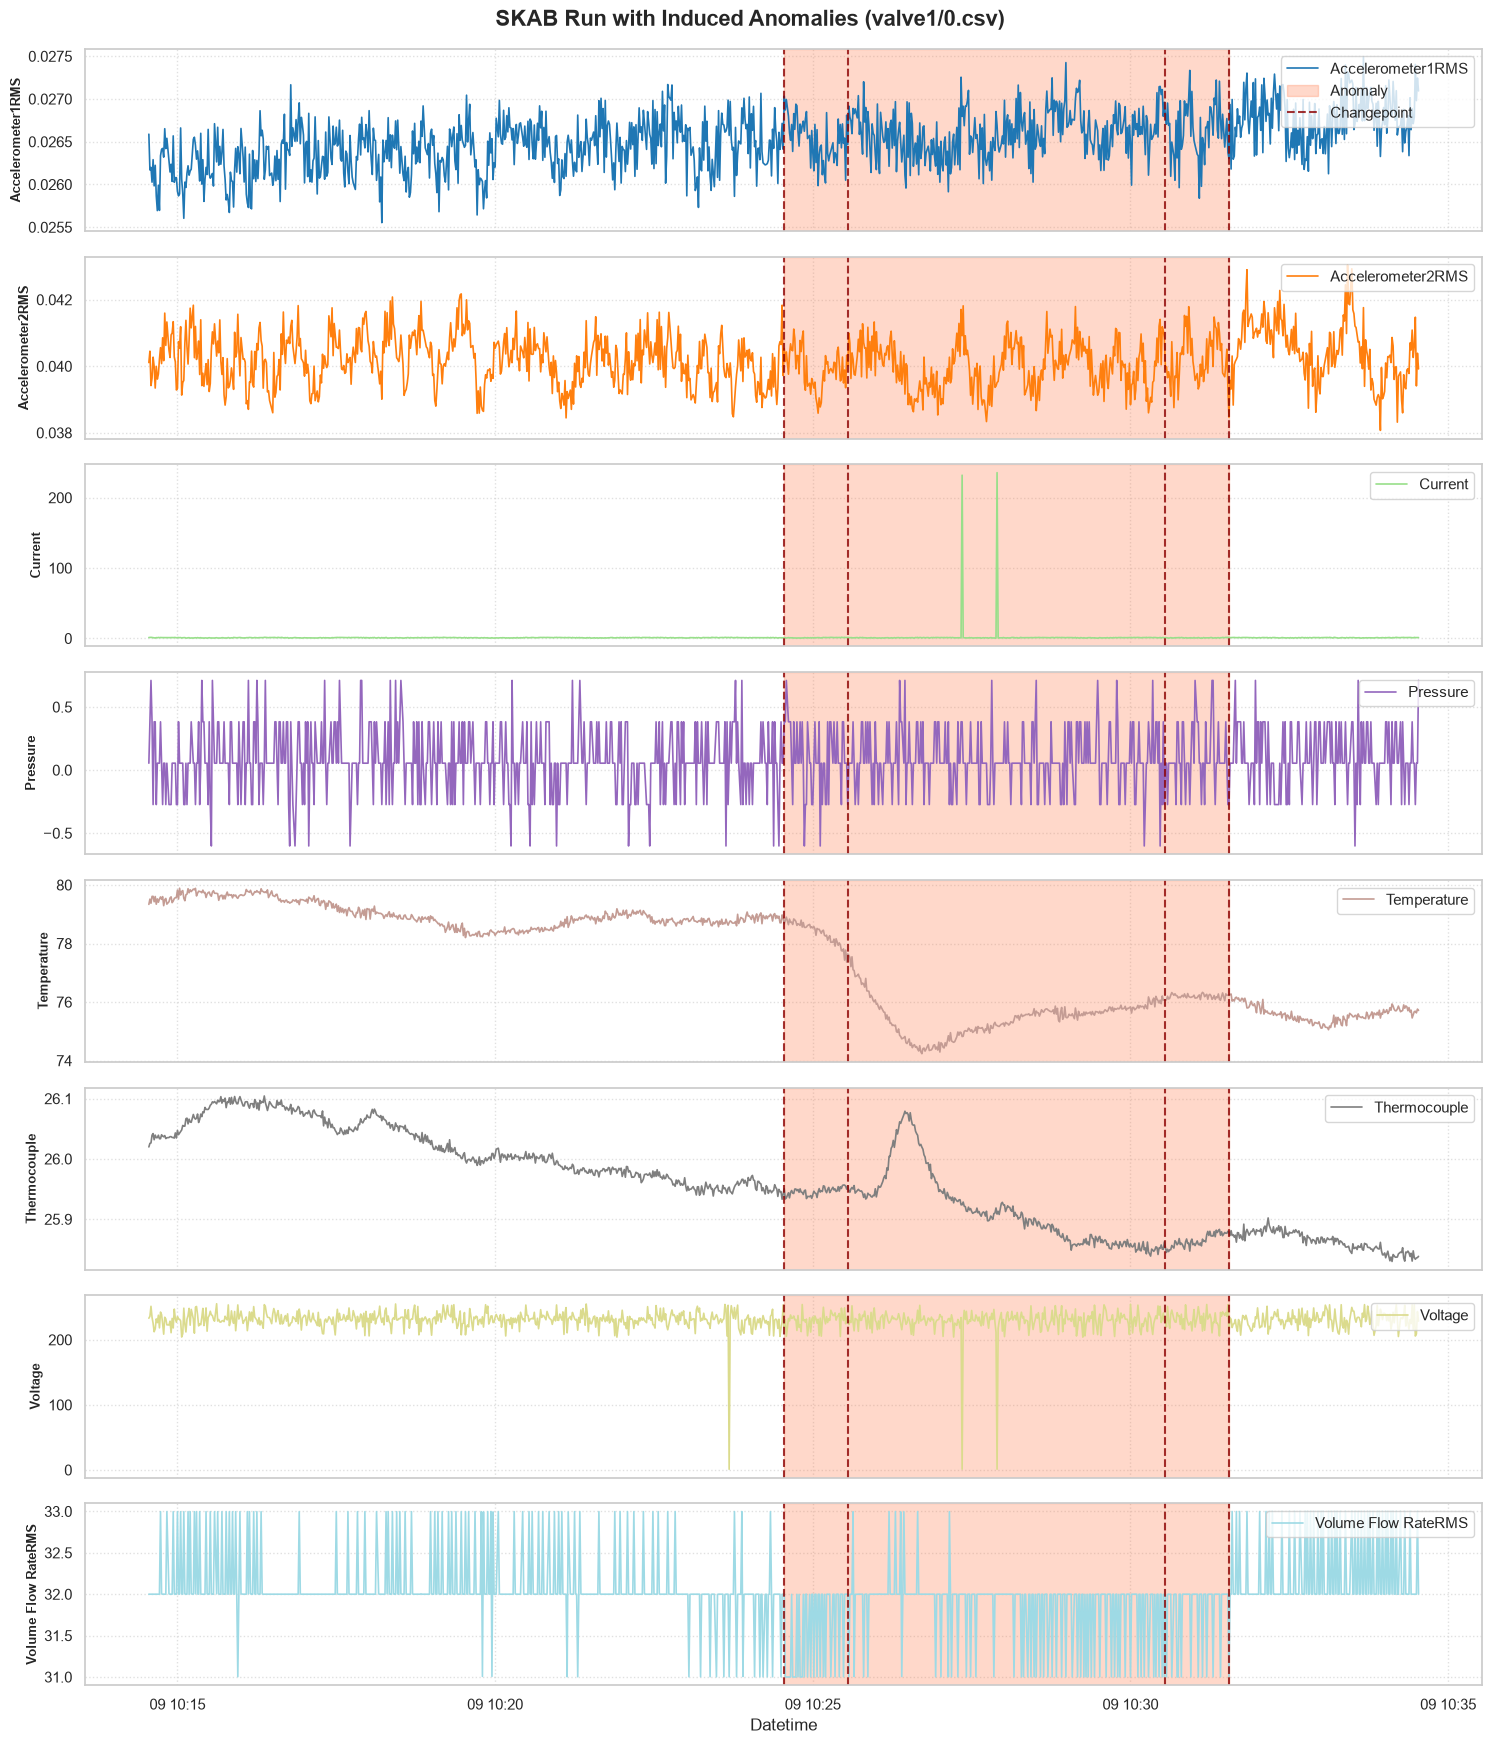

In [5]:
def plot_sensors(df, title):
    sensors = [col for col in df.columns if col not in ['anomaly', 'changepoint']]
    n_sensors = len(sensors)
    
    fig, axes = plt.subplots(n_sensors, 1, figsize=(15, 2.2 * n_sensors), sharex=True)
    if n_sensors == 1:
        axes = [axes]
        
    fig.suptitle(title, y=0.99, weight='bold', fontsize=16)
    
    # Extract anomaly blocks
    anomaly_blocks = []
    if 'anomaly' in df.columns:
        diff = df['anomaly'].diff().fillna(0)
        starts = df.index[diff == 1].tolist()
        ends = df.index[diff == -1].tolist()
        if df['anomaly'].iloc[0] == 1:
            starts.insert(0, df.index[0])
        if df['anomaly'].iloc[-1] == 1:
            ends.append(df.index[-1])
        anomaly_blocks = list(zip(starts, ends))
        
    # Extract changepoints
    changepoints = []
    if 'changepoint' in df.columns:
        changepoints = df.index[df['changepoint'] == 1].tolist()
        
    colors = plt.cm.tab20(np.linspace(0, 1, n_sensors))
    
    for i, (sensor, ax) in enumerate(zip(sensors, axes)):
        ax.plot(df.index, df[sensor], color=colors[i], label=sensor, linewidth=1.2)
        
        # Shading for anomalies
        for start, end in anomaly_blocks:
            ax.axvspan(start, end, color='coral', alpha=0.3, label='Anomaly' if i == 0 and start == anomaly_blocks[0][0] else "")
            
        # Vertical lines for changepoints
        for cp in changepoints:
            ax.axvline(cp, color='darkred', linestyle='--', linewidth=1.5, alpha=0.8, label='Changepoint' if i == 0 and cp == changepoints[0] else "")
            
        ax.set_ylabel(sensor, fontsize=9, weight='semibold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper right', frameon=True, framealpha=0.8)
        
    plt.xlabel('Datetime', fontsize=12)
    plt.tight_layout()
    plt.show()

# Plot the anomaly dataset
plot_sensors(df_anomaly, "SKAB Run with Induced Anomalies (valve1/0.csv)")

## 4. Feature Correlations
Let's look at how the different sensor readings correlate with each other during normal operation vs. during anomaly runs.

In [ ]:
def plot_correlation(df, title):
    sensors = [col for col in df.columns if col not in ['anomaly', 'changepoint']]
    corr = df[sensors].corr()
    
    plt.figure(figsize=(10, 8))
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                annot=True, fmt=".2f", square=True, linewidths=.5, cbar_kws={"shrink": .8})
    plt.title(title, fontsize=14, weight='bold', pad=15)
    plt.tight_layout()
    plt.show()

plot_correlation(df_clean, "Sensor Correlations - Anomaly-Free Run")
plot_correlation(df_anomaly, "Sensor Correlations - Valve1/0 Run")